# Mention-market validation: consolidated audit

This notebook consolidates the two original mention-market notebooks and audits the quantitative claims in:

- [Political Mention Market Calibration](../articles/political-mention-market-calibration.md)
- [Cross-Category Calibration Analysis](../articles/cross-category-calibration-analysis.md)

It uses two T7 evidence layers:

1. The repository loader over `/Volumes/T7/mention-markets`, which is the broad all-category snapshot available to the project.
2. `/Volumes/T7/mention-markets/longshot-audit/2026-10-02-validation`, a refreshed Trump-specific audit with API market metadata, trades, scheduled anchors, and decision rows through the 2026-10-01 trade tape.

The refreshed Trump audit is the primary evidence for the long-shot question. It records `settlement_ts` separately from `close_time`, excludes DNQ and unresolved contracts, and supplies a precomputed VWAP (`vwap_p`) at explicit horizons. The September 5 audit remains on T7 as a comparison snapshot. The broad loader is retained to reconcile the essay's cross-category claims.

**Executive finding.** The low-price side remains visible in the refreshed Trump audit: the 2-hour VWAP 25–35% band resolves YES below its mean implied probability. The high-price side is not present in the refreshed snapshot: the 70%+ band is essentially calibrated at 2 hours, with an event-cluster interval that crosses zero. The older broad T7 snapshot shows a much larger high-side gap, so the published claim is snapshot-sensitive and should be reported as historical evidence rather than a stable current trading rule.

In [1]:
from pathlib import Path
import sys, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = Path("/Users/lfpmb/Documents/mention-analysis")
if not (REPO / "src").exists():
    REPO = Path.cwd()
sys.path.insert(0, str(REPO))

from src.data_loading import load_markets, load_mention_markets
from src.mention_filters import get_category
from src.metrics import calibration_buckets, compute_mad, strategy_profits, kalshi_fee

T7_ROOT = Path("/Volumes/T7/mention-markets")
AUDIT_ROOT = T7_ROOT / "longshot-audit" / "2026-10-02-validation"
AUDIT_REFERENCE_ROOT = T7_ROOT / "longshot-audit" / "2026-09-04"
assert AUDIT_ROOT.exists(), f"Missing T7 audit directory: {AUDIT_ROOT}"
plt.style.use("seaborn-v0_8-whitegrid")


## 1. Provenance and inventory

The dates and grains below are part of the result. A count without a snapshot identifier is not a reproducible statistic.

In [2]:
collection = json.loads((AUDIT_ROOT / "collection.json").read_text())
root_market_files = [p for p in (T7_ROOT / "markets").glob("*.parquet") if not p.name.startswith("._")]
root_trade_files = [p for p in (T7_ROOT / "trades").glob("*.parquet") if not p.name.startswith("._")]
root_markets = load_markets()
root_vwap = load_mention_markets()
audit_markets = pd.read_parquet(AUDIT_ROOT / "markets.parquet")
audit_trades = pd.read_parquet(AUDIT_ROOT / "trades.parquet")
audit_decisions = pd.read_parquet(AUDIT_ROOT / "decision_rows.parquet")

inventory = pd.DataFrame([
    ["Broad T7 market files", len(root_market_files)],
    ["Broad T7 trade files", len(root_trade_files)],
    ["Broad raw market rows", len(root_markets)],
    ["Broad resolved market rows", int(root_markets.result.isin(["yes", "no"]).sum())],
    ["Broad rows with any trade/VWAP record", len(root_vwap)],
    ["Broad rows with 2h VWAP", int(root_vwap.vwap_2h.notna().sum())],
    ["Broad raw series values", int(root_markets.series.nunique())],
    ["Trump audit market rows", len(audit_markets)],
    ["Trump audit trade rows", len(audit_trades)],
    ["Trump audit decision rows", len(audit_decisions)],
    ["Trump audit decision events", int(audit_decisions.event_ticker.nunique())],
], columns=["measure", "value"])
display(inventory)
print("Broad close-time range:", root_markets.close_time.min(), "to", root_markets.close_time.max())
print("Broad VWAP close-time range:", root_vwap.close_time.min(), "to", root_vwap.close_time.max())
print("Trump audit collection:", collection["started_utc"], "to", collection["finished_utc"])
print("Trump audit trade max:", collection["trade_max_utc"])
print("Trump audit universe:", collection["universe"])


,measure,value
0,Broad T7 market files,141
1,Broad T7 trade files,141
2,Broad raw market rows,38450
3,Broad resolved market rows,36214
4,Broad rows with any trade/VWAP record,21975
5,Broad rows with 2h VWAP,20979
6,Broad raw series values,143
7,Trump audit market rows,9334
8,Trump audit trade rows,5012511
9,Trump audit decision rows,14433


Broad close-time range: 2025-01-30 12:55:29.003392-08:00 to 2026-08-08 07:00:00-07:00
Broad VWAP close-time range: 2025-01-30 12:55:29.003392-08:00 to 2026-07-05 12:09:59-07:00
Trump audit collection: 2026-10-02T08:57:04.118783+00:00 to 2026-10-02T08:57:56.686886+00:00
Trump audit trade max: 2026-10-01 22:51:26.751771+00:00
Trump audit universe: ['KXTRUMPMENTION', 'KXTRUMPMENTIONB']


## 2. Methodology and visual audit

The unit of analysis is a resolved contract at a specified VWAP horizon. A contract price is a probability-like market quote, so calibration must compare the observed YES rate with the **mean implied price of the observations in each bucket**. The fixed bucket midpoint is only a label; using it for MAD can create error when prices cluster within a bucket.

The loader now computes each VWAP from trades at or before `last_trade_time − horizon`. This is a **cumulative pre-cutoff VWAP**: it includes all qualifying earlier trades, rather than only the trailing interval `[anchor − horizon, anchor]`. It answers “what was the cumulative traded price at least N hours before trading stopped?” It does not answer “what was the price N hours before Trump spoke,” does not use settlement time as an event clock, and does not establish that the VWAP was an executable fill. If a trailing-window VWAP is intended, the SQL must use both lower and upper time bounds and the full analysis must be recomputed. The audit therefore treats the current VWAP as a retrospective benchmark and keeps spread, depth, slippage, queue position, and event clustering as limitations.

The corrected calibration graphics use a numeric 0–100% x-axis with the 45-degree perfect-calibration line and plot within-bucket mean implied probabilities. The older categorical bucket-index plots visually treated equal-width bins as equally spaced even when their observed prices were not centered at the midpoint. The MAD chart now orders horizons from long lookback to short lookback without reversing the axis, and labels the anchor as the final recorded trade. VWAP spaghetti plots remain useful diagnostics, but their paths have unequal horizon coverage and are not event-aligned trajectories. Weekly calibration-over-time charts are cumulative trade-position snapshots using both sides of trades; they are not independent contract-level time series.


## 3. Broad-snapshot data quality and category reconciliation

The original cross-category counts are historical outputs of the older notebooks. The current loader has more rows and the category map is incomplete for newly appearing series. Trump is canonicalized by ticker prefix so metadata values `A` and `B` are not silently lost.

In [3]:
root = root_vwap.copy()
root["actual_yes"] = root["result"].eq("yes")
root["category"] = root.apply(
    lambda row: "Politicians" if str(row["ticker"]).startswith("KXTRUMPMENTION") else get_category(row["series"]),
    axis=1,
)
root_valid = root.dropna(subset=["vwap_2h"]).copy()
root_valid["pred_yes"] = root_valid["vwap_2h"] >= 50

category_profile = (root_valid.groupby("category")
    .agg(contracts=("ticker", "size"), yes_rate=("actual_yes", "mean"),
         directional_accuracy=("pred_yes", lambda s: (s == root_valid.loc[s.index, "actual_yes"]).mean()),
         mean_vwap=("vwap_2h", "mean"))
    .sort_index())
category_profile[["yes_rate", "directional_accuracy"]] *= 100
category_profile = category_profile.round(2)
display(category_profile)

series_audit = (root.loc[root.ticker.astype(str).str.startswith("KXTRUMPMENTION")]
    .groupby("series", dropna=False).agg(rows=("ticker", "size"), resolved=("actual_yes", "count")))
display(series_audit)

# Broad loader's last-trade lag is a trading-stop diagnostic, not a payout lag.
root["close_time_utc"] = pd.to_datetime(root["close_time"], utc=True)
root["last_trade_time_utc"] = pd.to_datetime(root["last_trade_time"], utc=True)
lag = (root["close_time_utc"] - root["last_trade_time_utc"]).dt.total_seconds() / 60
lag_pos = lag.dropna().loc[lambda s: s >= 0]
lag_table = pd.DataFrame({
    "measure": ["rows with lag", "negative close-minus-last-trade", "median positive lag (min)", ">1 hour", ">4 hours"],
    "value": [int(lag.notna().sum()), int((lag < 0).sum()), round(lag_pos.median(), 1), round((lag_pos > 60).mean() * 100, 1), round((lag_pos > 240).mean() * 100, 1)],
})
display(lag_table)

unmapped = (root_valid[root_valid.category == "Other"].groupby("series").size().sort_values(ascending=False).head(15).rename("valid_2h_rows").to_frame())
display(unmapped)


,contracts,yes_rate,directional_accuracy,mean_vwap
category,,,,
Earnings,2118,57.37,88.48,60.95
Entertainment,1228,32.33,92.59,40.43
Finance,559,39.00,86.58,46.06
Media/News,757,40.82,83.49,49.88
Other,663,41.03,86.58,46.67
Politicians,10271,44.05,82.84,48.50
Sports,5383,52.03,87.29,57.76


,rows,resolved
series,,
A,1267,1267
B,460,460
KXTRUMPMENTION,4812,4812


,measure,value
0,rows with lag,21975.0
1,negative close-minus-last-trade,232.0
2,median positive lag (min),58.0
3,>1 hour,49.3
4,>4 hours,21.2


,valid_2h_rows
series,
KXSTARMERMENTION,112
KXBILATERALMENTION,64
KXJOHNSONMENTION,50
KXUNMENTION,35
KXZELENSKYYMENTION,31
KXCANDEBMENTION,30
KXVLADTENEVMENTION,28
KXDJTNATOMENTION,28
KXBARRMENTION,26


## 4. Settlement timestamps in the newer Trump audit

The newer audit supplies `settlement_ts`. `close_time` is the end of trading and `settlement_ts` is the payout/settlement timestamp in this extract. The old essays call `close_time` settlement and compare it with `last_trade_time`; that is a timestamp-definition problem. The calibration analysis below does not anchor VWAPs to either settlement timestamp; it uses the audit decision rows.

In [4]:
audit_markets["close_time"] = pd.to_datetime(audit_markets["close_time"], utc=True)
audit_markets["settlement_ts"] = pd.to_datetime(audit_markets["settlement_ts"], utc=True)
settle_lag = (audit_markets["settlement_ts"] - audit_markets["close_time"]).dt.total_seconds() / 60
settle_pos = settle_lag.dropna().loc[lambda s: s >= 0]
settlement_quality = pd.DataFrame({
    "measure": ["market rows", "resolved", "DNQ", "missing settlement_ts", "negative settlement-minus-close", "median nonnegative settlement lag (min)", ">1 hour", ">4 hours", "volume mismatch rows in coverage audit"],
    "value": [len(audit_markets), int(audit_markets.is_resolved.sum()), int(audit_markets.is_dnq.sum()), int(audit_markets.settlement_ts.isna().sum()), int((settle_lag < 0).sum()), round(settle_pos.median(), 1), round((settle_pos > 60).mean() * 100, 1), round((settle_pos > 240).mean() * 100, 1), int((pd.read_parquet(AUDIT_ROOT / "trade_coverage.parquet").volume_difference.abs() > 0.001).sum())]
})
display(settlement_quality)
print("Three settlement spot checks:")
display(pd.DataFrame(json.loads((AUDIT_ROOT / "settlement_spot_checks.json").read_text())))


,measure,value
0,market rows,9334.0
1,resolved,9086.0
2,DNQ,160.0
3,missing settlement_ts,204.0
4,negative settlement-minus-close,0.0
5,median nonnegative settlement lag (min),30.2
6,>1 hour,17.4
7,>4 hours,8.5
8,volume mismatch rows in coverage audit,44.0


Three settlement spot checks:


,ticker,saved_result,fresh_result,checked_utc,endpoint
0,KXTRUMPMENTION-26JUL24-UFC,yes,yes,2026-10-02T09:04:11.521136+00:00,/historical/markets/KXTRUMPMENTION-26JUL24-UFC
1,KXTRUMPMENTION-26JUL24-CLIN,no,no,2026-10-02T09:04:11.658935+00:00,/historical/markets/KXTRUMPMENTION-26JUL24-CLIN
2,KXTRUMPMENTION-26JUL24-BIDE,yes,yes,2026-10-02T09:04:11.784791+00:00,/historical/markets/KXTRUMPMENTION-26JUL24-BIDE


## 5. Trump calibration in the newest audit

The primary estimate uses `vwap_p` as the implied probability and `y` as the resolved outcome. Rows are already resolved and non-DNQ in the saved decision table. Uncertainty is clustered by `event_ticker`: many word contracts from one speech are correlated, so contract-level binomial intervals would be too narrow.

In [5]:
def event_cluster_bootstrap(frame, n_boot=4000, seed=7):
    """Contract-weighted event bootstrap for mean(actual - implied)."""
    grouped = frame.groupby("event_ticker").agg(
        y_sum=("y", "sum"), p_sum=("vwap_p", "sum"), n=("y", "size")
    )
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(grouped), size=(n_boot, len(grouped)))
    y_sum = grouped.y_sum.to_numpy()[indices].sum(axis=1)
    p_sum = grouped.p_sum.to_numpy()[indices].sum(axis=1)
    n = grouped.n.to_numpy()[indices].sum(axis=1)
    return np.quantile((y_sum - p_sum) / n, [0.025, 0.5, 0.975])

def band_row(frame, horizon, label, mask):
    z = frame.loc[mask].dropna(subset=["vwap_p", "y"]).copy()
    if z.empty:
        return {"horizon_h": horizon, "band": label, "contracts": 0, "events": 0, "mean_p_pct": np.nan, "yes_pct": np.nan, "error_pp": np.nan, "boot_95_low_pp": np.nan, "boot_95_high_pp": np.nan}
    interval = event_cluster_bootstrap(z) * 100
    return {"horizon_h": horizon, "band": label, "contracts": len(z), "events": z.event_ticker.nunique(), "mean_p_pct": z.vwap_p.mean() * 100, "yes_pct": z.y.mean() * 100, "error_pp": (z.y.mean() - z.vwap_p.mean()) * 100, "boot_95_low_pp": interval[0], "boot_95_high_pp": interval[2]}

resolved = audit_decisions.loc[
    audit_decisions.is_resolved & ~audit_decisions.is_dnq
].copy()
calibration_rows = []
for horizon, frame in resolved.groupby("horizon_hours"):
    frame = frame.dropna(subset=["vwap_p", "y"])
    calibration_rows.extend([
        band_row(frame, horizon, "25–35%", (frame.vwap_p >= .25) & (frame.vwap_p < .35)),
        band_row(frame, horizon, "70–80%", (frame.vwap_p >= .70) & (frame.vwap_p < .80)),
        band_row(frame, horizon, "70%+", frame.vwap_p >= .70),
    ])
calibration_table = pd.DataFrame(calibration_rows)
for col in ["mean_p_pct", "yes_pct", "error_pp", "boot_95_low_pp", "boot_95_high_pp"]:
    calibration_table[col] = calibration_table[col].round(2)
display(calibration_table)


,horizon_h,band,contracts,events,mean_p_pct,yes_pct,error_pp,boot_95_low_pp,boot_95_high_pp
0,1,25–35%,485,132,29.96,20.82,-9.13,-13.11,-4.88
1,1,70–80%,401,124,75.05,73.07,-1.98,-7.31,3.17
2,1,70%+,871,135,81.58,81.29,-0.30,-4.18,3.11
3,2,25–35%,461,124,29.94,24.51,-5.43,-9.78,-1.07
4,2,70–80%,389,123,74.95,74.29,-0.65,-6.41,4.70
5,2,70%+,803,131,81.13,81.07,-0.06,-4.18,3.53
6,6,25–35%,329,99,29.90,24.92,-4.98,-10.53,0.66
7,6,70–80%,298,102,74.75,74.16,-0.59,-7.53,5.59
8,6,70%+,609,109,80.86,79.31,-1.55,-7.14,3.10
9,12,25–35%,214,69,29.86,23.36,-6.49,-13.60,1.17


### Snapshot comparison

The prior September audit is retained to show how much of the apparent favorite-side effect depends on the data cutoff. Both snapshots use the same decision-row construction and 2-hour bands.

In [6]:
def snapshot_band(frame, snapshot, label, mask):
    z = frame.loc[mask].dropna(subset=["vwap_p", "y"])
    interval = event_cluster_bootstrap(z) * 100
    return {"snapshot": snapshot, "band": label, "contracts": len(z), "events": z.event_ticker.nunique(), "mean_p_pct": z.vwap_p.mean() * 100, "yes_pct": z.y.mean() * 100, "error_pp": (z.y.mean() - z.vwap_p.mean()) * 100, "boot_95_low_pp": interval[0], "boot_95_high_pp": interval[2]}

reference_decisions = pd.read_parquet(AUDIT_REFERENCE_ROOT / "decision_rows.parquet")
comparison_rows = []
for snapshot, frame in [("2026-09-04", reference_decisions), ("2026-10-02", audit_decisions)]:
    frame = frame.loc[frame.horizon_hours.eq(2)].dropna(subset=["vwap_p", "y"])
    comparison_rows.extend([
        snapshot_band(frame, snapshot, "25–35%", frame.vwap_p.between(.25, .35, inclusive="left")),
        snapshot_band(frame, snapshot, "70%+", frame.vwap_p.ge(.70)),
    ])
comparison_table = pd.DataFrame(comparison_rows)
for col in ["mean_p_pct", "yes_pct", "error_pp", "boot_95_low_pp", "boot_95_high_pp"]:
    comparison_table[col] = comparison_table[col].round(2)
display(comparison_table)


,snapshot,band,contracts,events,mean_p_pct,yes_pct,error_pp,boot_95_low_pp,boot_95_high_pp
0,2026-09-04,25–35%,440,117,29.94,23.41,-6.53,-10.84,-2.28
1,2026-09-04,70%+,759,123,81.14,81.69,0.54,-3.51,4.24
2,2026-10-02,25–35%,461,124,29.94,24.51,-5.43,-9.78,-1.07
3,2026-10-02,70%+,803,131,81.13,81.07,-0.06,-4.18,3.53


,band,contracts,events,mean_p,yes_rate,error_pp
0,"[0.0, 0.1)",244,101,5.59,4.10,-1.49
1,"[0.1, 0.2)",334,115,15.24,14.07,-1.17
2,"[0.2, 0.3)",469,122,25.05,17.06,-8.00
3,"[0.3, 0.4)",447,124,35.02,31.10,-3.92
4,"[0.4, 0.5)",366,119,44.87,35.79,-9.08
5,"[0.5, 0.6)",424,133,54.97,42.92,-12.04
6,"[0.6, 0.7)",430,125,65.27,59.30,-5.97
7,"[0.7, 0.8)",387,122,74.97,74.16,-0.81
8,"[0.8, 0.9)",316,107,84.99,84.81,-0.18
9,"[0.9, 1.0)",98,56,93.20,95.92,2.72


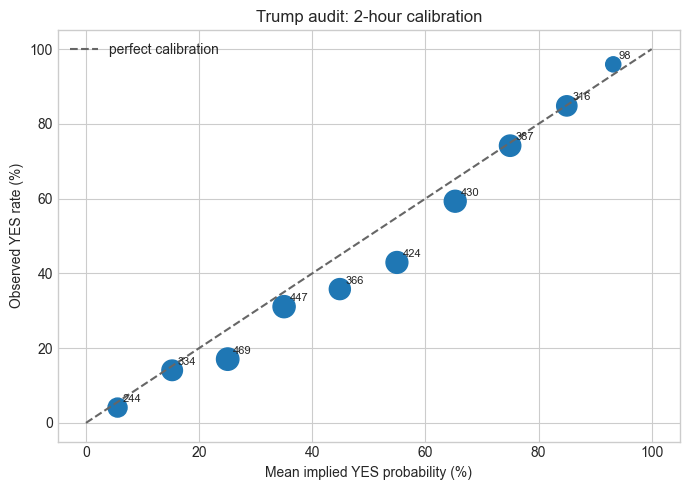

In [7]:
two_hour = resolved.loc[resolved.horizon_hours.eq(2)].dropna(subset=["vwap_p", "y"]).copy()
bins = np.arange(0, 1.01, .10)
two_hour["band"] = pd.cut(two_hour.vwap_p, bins=bins, include_lowest=True, right=False)
decile = (two_hour.groupby("band", observed=False)
    .agg(contracts=("y", "size"), events=("event_ticker", "nunique"), mean_p=("vwap_p", "mean"), yes_rate=("y", "mean"))
    .reset_index())
decile["error_pp"] = (decile.yes_rate - decile.mean_p) * 100
decile[["mean_p", "yes_rate"]] *= 100
display(decile.round(2))

fig, ax = plt.subplots(figsize=(7, 5))
plot_data = decile.dropna(subset=["mean_p", "yes_rate"])
ax.plot([0, 100], [0, 100], "--", color="0.4", label="perfect calibration")
ax.scatter(plot_data.mean_p, plot_data.yes_rate, s=np.sqrt(plot_data.contracts) * 12, color="#1f77b4")
for _, row in plot_data.iterrows():
    ax.annotate(int(row.contracts), (row.mean_p, row.yes_rate), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="Mean implied YES probability (%)", ylabel="Observed YES rate (%)", title="Trump audit: 2-hour calibration")
ax.legend()
fig.tight_layout()
plt.show()


### Recency sensitivity

The full-history estimate can hide a regime change. The newest audit is cut into a recent 90-day slice using the latest available `event_day`; this is descriptive and has fewer independent events.

In [8]:
resolved["event_day"] = pd.to_datetime(resolved["event_day"], utc=True)
recent_cut = resolved.event_day.max() - pd.Timedelta(days=90)
recent = resolved.loc[resolved.event_day >= recent_cut]
recent_rows = []
for horizon, frame in recent.groupby("horizon_hours"):
    frame = frame.dropna(subset=["vwap_p", "y"])
    recent_rows.extend([
        band_row(frame, horizon, "25–35%", (frame.vwap_p >= .25) & (frame.vwap_p < .35)),
        band_row(frame, horizon, "70%+", frame.vwap_p >= .70),
    ])
recent_table = pd.DataFrame(recent_rows)
for col in ["mean_p_pct", "yes_pct", "error_pp", "boot_95_low_pp", "boot_95_high_pp"]:
    recent_table[col] = recent_table[col].round(2)
print("Recent slice:", recent_cut.date(), "through", resolved.event_day.max().date())
display(recent_table)


Recent slice: 2026-07-02 through 2026-09-30


,horizon_h,band,contracts,events,mean_p_pct,yes_pct,error_pp,boot_95_low_pp,boot_95_high_pp
0,1,25–35%,120,29,29.86,21.67,-8.19,-16.07,0.38
1,1,70%+,151,29,80.78,79.47,-1.31,-10.83,6.29
2,2,25–35%,115,28,29.36,26.96,-2.40,-11.58,7.59
3,2,70%+,146,27,79.95,78.77,-1.19,-11.43,6.69
4,6,25–35%,79,19,29.64,31.65,2.01,-10.67,12.25
5,6,70%+,92,21,78.65,70.65,-8.00,-21.09,3.27
6,12,25–35%,73,16,29.91,28.77,-1.14,-15.87,14.22
7,12,70%+,57,15,77.61,63.16,-14.46,-36.58,2.16
8,24,25–35%,16,5,29.68,50.00,20.32,-6.33,51.17
9,24,70%+,11,4,78.55,81.82,3.26,-15.73,22.31


## 6. Corrected cross-category calibration

The broad snapshot can reproduce the category structure, but its current counts are different from the essay. The corrected MAD uses the mean implied probability within each bucket; the fixed midpoint remains a plotting label. This distinction matters because prices are not uniformly distributed inside a 10-cent bucket.

In [9]:
category_rows = []
for category, frame in root_valid.groupby("category"):
    cal = calibration_buckets(frame, "vwap_2h", actual_col="actual_yes", bin_size=10)
    category_rows.append({
        "category": category,
        "contracts": len(frame),
        "events": frame.ticker.str.rsplit("-", n=1).str[0].nunique(),
        "yes_rate_pct": frame.actual_yes.mean() * 100,
        "directional_accuracy_pct": frame.pred_yes.eq(frame.actual_yes).mean() * 100,
        "corrected_mad_pp": compute_mad(cal),
    })
category_table = pd.DataFrame(category_rows).sort_values("category")
display(category_table.round(2))


,category,contracts,events,yes_rate_pct,directional_accuracy_pct,corrected_mad_pp
0,Earnings,2118,159,57.37,88.48,12.17
1,Entertainment,1228,86,32.33,92.59,16.50
2,Finance,559,30,39.00,86.58,11.58
3,Media/News,757,71,40.82,83.49,10.78
4,Other,663,51,41.03,86.58,12.78
5,Politicians,10271,512,44.05,82.84,8.60
6,Sports,5383,317,52.03,87.29,11.95


## 7. Strategy audit

The old notebooks evaluate thresholds on the same observations used to discover the calibration pattern. The table below is an in-sample fee-adjusted benchmark over the broad current snapshot. It is useful as a descriptive accounting check, not as a live return estimate. The newer Trump audit then uses a chronological event split to show why a threshold result needs out-of-sample validation.

In [10]:
root_strategy = pd.concat([
    strategy_profits(root_valid, price_col="vwap_2h", actual_col="actual_yes", thresholds=[50, 60, 70, 80, 90], side="yes").assign(side="YES"),
    strategy_profits(root_valid, price_col="vwap_2h", actual_col="actual_yes", thresholds=[20, 30, 40, 50, 60], side="no").assign(side="NO"),
], ignore_index=True)
display(root_strategy[["side", "threshold", "trades", "net_pnl_per_trade", "net_return", "hit_rate"]].round(4))

# Chronological split on the newest Trump audit, fixed pre-specified thresholds.
trump_2h = resolved.loc[resolved.horizon_hours.eq(2)].dropna(subset=["vwap_p", "y"]).copy()
trump_2h["event_day"] = pd.to_datetime(trump_2h["event_day"], utc=True)
split_date = trump_2h.event_day.quantile(.70)
trump_2h["split"] = np.where(trump_2h.event_day <= split_date, "train", "test")

def benchmark(frame, side, threshold):
    p = frame.vwap_p.to_numpy() * 100
    y = frame.y.to_numpy()
    eligible = p > threshold if side == "YES" else p < threshold
    if not eligible.any():
        return {"trades": 0, "net_pnl_cents": 0.0, "net_pnl_per_trade": np.nan, "hit_rate": np.nan}
    prices = p[eligible]
    wins = y[eligible] if side == "YES" else 1 - y[eligible]
    entry = prices if side == "YES" else 100 - prices
    fees = np.array([kalshi_fee(x) for x in entry])
    pnl = wins * 100 - entry - fees
    return {"trades": len(pnl), "net_pnl_cents": pnl.sum(), "net_pnl_per_trade": pnl.mean(), "hit_rate": (pnl > 0).mean()}

split_rows = []
for split, frame in trump_2h.groupby("split"):
    for side, threshold in [("YES", 70), ("NO", 40)]:
        row = benchmark(frame, side, threshold)
        split_rows.append({"split": split, "side": side, "threshold": threshold, **row})
split_table = pd.DataFrame(split_rows)
print("Chronological split date:", split_date.date())
display(split_table.round(3))


,side,threshold,trades,net_pnl_per_trade,net_return,hit_rate
0,YES,50,10815,1.6003,0.0202,0.8083
1,YES,60,9159,3.9817,0.0478,0.8721
2,YES,70,7313,5.1338,0.0588,0.9242
3,YES,80,5285,4.8281,0.0530,0.9601
4,YES,90,2797,3.5389,0.0371,0.9882
5,NO,20,4443,8.1371,0.0904,0.9820
6,NO,30,6703,10.2058,0.1191,0.9590
7,NO,40,8558,11.7597,0.1440,0.9343
8,NO,50,10158,12.4171,0.1596,0.9022
9,NO,60,11820,11.7477,0.1599,0.8521


Chronological split date: 2026-06-10


,split,side,threshold,trades,net_pnl_cents,net_pnl_per_trade,hit_rate
0,test,YES,70,176,-323.618,-1.839,0.795
1,test,NO,40,522,1152.553,2.208,0.808
2,train,YES,70,625,-1055.893,-1.689,0.814
3,train,NO,40,972,2594.312,2.669,0.811


## 8. Essay claim ledger

The ledger distinguishes historical reproduction from current validity. “Historical / metric issue” means the number can be reproduced from the executed notebooks but is mislabeled or not the statistic the prose claims. “Supported with caveat” means the direction appears in the newest audit but the full interpretation needs narrower wording.

In [11]:
claim_ledger = pd.DataFrame([
    ["Political universe = 7,320; Trump = 3,401", "Historical / stale", "Matches the original executed political notebook's snapshot, not the current broad snapshot or the newer Trump audit.", "Record snapshot date and manifest; rerun from canonical ticker/event universe."],
    ["Cross-category universe = 18,948 from 35,837 raw / 33,587 resolved", "Historical / stale", "Matches the original notebook output, but current broad loader has 38,450 raw, 36,214 resolved, and 20,979 valid 2h rows.", "Publish counts with snapshot ID, cutoff, and valid-VWAP denominator."],
    ["Trump is exactly series KXTRUMPMENTION", "Incorrect filter", "Current broad metadata stores Trump rows under KXTRUMPMENTION, A, and B; exact-series filtering misses A/B.", "Canonicalize with ticker prefix plus an explicit series audit."],
    ["30% contracts are overestimated", "Supported with caveat", "Refreshed audit 2h 25–35%: mean implied 29.94%, observed YES 24.51%, error −5.43 pp; event bootstrap is −9.78 to −1.02 pp.", "Use within-band mean p, event-cluster uncertainty, and a fixed horizon."],
    ["70%+ contracts happen much more than 70%", "Not established in newest audit", "Refreshed audit 2h 70%+: mean implied 81.13%, observed YES 81.07%, error −0.06 pp; bootstrap −4.12 to +3.54 pp.", "Treat the older positive estimate as historical/snapshot-sensitive; require a preregistered holdout."],
    ["Overall MAD = 5.35 pp; recent 8 weeks = 3.26 pp", "Misinterpreted statistic", "These are means of cumulative weekly MAD snapshots, not one contract-level overall MAD and not a last-8-week cohort MAD.", "Report cohort-by-week calibration and label cumulative curves as cumulative."],
    ["Median settlement lag = 71 minutes", "Timestamp/denominator issue", "The old metric is close_time minus last_trade_time and excludes negative lags in the headline denominator; the refreshed audit has settlement_ts and a 30.2-minute nonnegative settlement-minus-close median (17.4% over one hour; 8.5% over four hours).", "Use close_time for trading stop, settlement_ts for payout, and show all missing/negative cases."],
    ["Every category improves monotonically toward 10 minutes", "Unsupported generalization", "The current decision table has horizon-specific denominators and non-monotonic errors; monotonicity needs a paired test with comparable contracts.", "Report per-horizon n, mean p, event counts, confidence intervals, and a formal trend test."],
    ["+5.0¢ YES and +14.1¢ NO are pooled per-trade returns", "Incorrect aggregation", "The original subgroup/category summary averages group means while displaying summed contracts; it is not total PnL divided by total trades.", "Pool at contract/trade grain: total net PnL / total eligible contracts; keep equal-group means separate."],
    ["Positive fee-adjusted returns imply a tradeable edge", "Not established", "VWAP benchmarks are retrospective and omit fill size, spread, slippage, queue position, and event concentration. Chronological Trump 2h results change sign by split for YES >70.", "Pre-specify thresholds, split by event date, and model executable fills and event-level drawdown."],
    ["Causal explanations: learning, liquidity, asymmetric information", "Hypothesis only", "Calibration tables identify association, not mechanism or causality.", "Reword as hypotheses and test with liquidity, participation, and event controls."],
], columns=["essay claim", "status", "validation evidence", "repair"])
display(claim_ledger)


,essay claim,status,validation evidence,repair
0,"Political universe = 7,320; Trump = 3,401",Historical / stale,Matches the original executed political notebo...,Record snapshot date and manifest; rerun from ...
1,"Cross-category universe = 18,948 from 35,837 r...",Historical / stale,"Matches the original notebook output, but curr...","Publish counts with snapshot ID, cutoff, and v..."
2,Trump is exactly series KXTRUMPMENTION,Incorrect filter,Current broad metadata stores Trump rows under...,Canonicalize with ticker prefix plus an explic...
3,30% contracts are overestimated,Supported with caveat,Refreshed audit 2h 25–35%: mean implied 29.94%...,"Use within-band mean p, event-cluster uncertai..."
4,70%+ contracts happen much more than 70%,Not established in newest audit,"Refreshed audit 2h 70%+: mean implied 81.13%, ...",Treat the older positive estimate as historica...
5,Overall MAD = 5.35 pp; recent 8 weeks = 3.26 pp,Misinterpreted statistic,These are means of cumulative weekly MAD snaps...,Report cohort-by-week calibration and label cu...
6,Median settlement lag = 71 minutes,Timestamp/denominator issue,The old metric is close_time minus last_trade_...,"Use close_time for trading stop, settlement_ts..."
7,Every category improves monotonically toward 1...,Unsupported generalization,The current decision table has horizon-specifi...,"Report per-horizon n, mean p, event counts, co..."
8,+5.0¢ YES and +14.1¢ NO are pooled per-trade r...,Incorrect aggregation,The original subgroup/category summary average...,Pool at contract/trade grain: total net PnL / ...
9,Positive fee-adjusted returns imply a tradeabl...,Not established,VWAP benchmarks are retrospective and omit fil...,"Pre-specify thresholds, split by event date, a..."


## 8. Interpretation and repair plan

The evidence supports a narrower conclusion than the essays currently state. In the newest Trump audit, low-probability YES contracts are materially overestimated around 30% at the 2-hour horizon. That is consistent with a long-shot bias on the low side. The corresponding favorite-side statement is not confirmed in that same audit: the 70%+ result is close to calibrated at 2 hours and the event-cluster interval includes zero. The older broad snapshot's +8.2 pp high-side estimate is useful historical evidence, but the difference between snapshots means it should not be presented as a persistent live effect.

The original essays also combine several distinct denominators: raw markets, resolved markets, markets with trades, markets with a valid VWAP, trade positions, and contracts. Every table should name its denominator. Contract counts should not be treated as independent observations when many contracts belong to one speech. The primary uncertainty unit should be `event_ticker`.

The practical repair sequence is:

1. Freeze the source manifest, API cutoff, timezone, and schema for each run.
2. Canonicalize market identity by ticker prefix and join `event_ticker`; maintain a versioned series/category map and an unmapped-series table.
3. Use `settlement_ts` for payout timing and `close_time` for trading cessation. Use the final trade only when the research question is explicitly “before trading stopped.”
4. Compute calibration error from the within-bucket mean implied probability. Keep bucket midpoints only for chart labels.
5. Declare one primary horizon before looking at results; report other horizons as sensitivity checks with their own denominators.
6. Use event-cluster bootstrap or event-level aggregation for uncertainty.
7. Separate discovery from evaluation with chronological event splits. A strategy table must report total PnL, total wagered, net return, per-contract PnL, fills, and event-level drawdowns.
8. Treat the current long-shot result as a descriptive calibration finding until an untouched holdout and executable fill simulation reproduce it.

The source helper `src/metrics.py` now records the within-bucket mean implied probability and uses it for corrected MAD calculations while retaining the midpoint for plotting compatibility.

## Sources and reproducibility

- Broad T7 source: `/Volumes/T7/mention-markets`
- New Trump audit: `/Volumes/T7/mention-markets/longshot-audit/2026-10-02-validation`
- Prior Trump comparison audit: `/Volumes/T7/mention-markets/longshot-audit/2026-09-04`
- Kalshi fee schedule: [kalshi.com/docs/kalshi-fee-schedule.pdf](https://kalshi.com/docs/kalshi-fee-schedule.pdf)
- Published essays: [political mention calibration](https://lfpmb.com/articles/political-mention-market-calibration) and [cross-category calibration](https://lfpmb.com/articles/cross-category-calibration-analysis)

Run the notebook from the repository root with the T7 drive mounted. The broad loader ignores macOS `._*.parquet` sidecars and the notebook fails early if the audit directory is unavailable.